# Combining error detection with error cancellation

Spacetime Pauli checks detect errors and post-selection discards them, but only the errors the checks can see. Probabilistic error cancellation (PEC) removes the rest in expectation, at a sampling cost $\gamma^2$ that grows exponentially with the total noise it has to invert. Combined, the two divide the noise between them: the checks take what they detect, PEC inverts only the undetected remainder, and its overhead drops from $\gamma^2$ to a much smaller $\gamma'^2$. This guide builds that combination from a `CheckedCircuit` with `samplomatic` and `qiskit-mitigation`, shows that it beats either method alone, and ends by computing the one systematic error it leaves behind: the mask that removes detected generators from the noise model is a first-order statement, and two detected errors can combine into one the checks miss.

The circuit is simulated with Qiskit Aer, and the noise model handed to the mitigation *is* the noise the simulator applies, so every deviation from the exact answer is the method's own. On hardware the maps come from noise learning instead; everything else is unchanged.

The workflow is as follows:
1. Build a Clifford circuit whose exact expectation values are known.
2. Model the device noise with one Pauli-Lindblad map per entangling layer.
3. Add Pauli checks to the circuit.
4. Box the circuit for sampling and shade its noise model by detectability.
5. Sample the twirled circuit with and without noise inversion.
6. Undo the measurement twirl and post-select on the checks.
7. Estimate the expectation values and compare the four methods.
8. Compute the first-order truncation bias.

### 1. Build a circuit with a known answer

A random brickwork Clifford circuit followed by its inverse returns every qubit to $|0\rangle$, so $\langle Z_q \rangle = 1$ exactly for every qubit, while the noisy circuit is as deep and as entangling as any other. The deviation of any estimate from $1$ is therefore its error. The two unique entangling layers, the even and the odd edges of the chain, are recorded as `payload_layers` so that the boxing step can reproduce them.

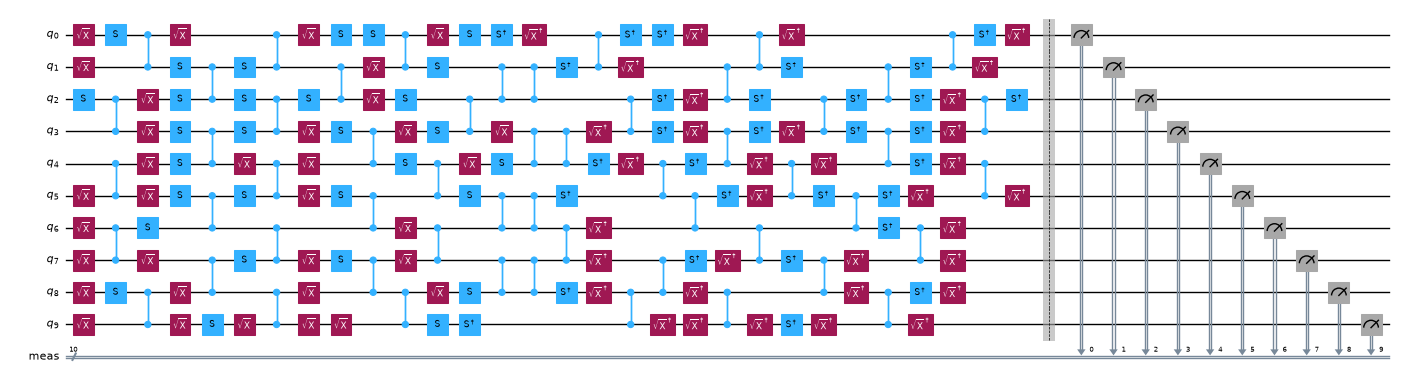

In [1]:
import numpy as np
from qiskit import QuantumCircuit

NUM_QUBITS, FORWARD_LAYERS, SEED = 10, 6, 1234


def mirror_brickwork(num_qubits, num_layers, rng):
    """A random brickwork Clifford circuit followed by its inverse, then measured."""
    forward = QuantumCircuit(num_qubits)
    for layer in range(num_layers):
        for qubit in range(num_qubits):
            if rng.integers(0, 2):
                forward.sx(qubit)
            if rng.integers(0, 2):
                forward.s(qubit)
        for qubit in range(layer % 2, num_qubits - 1, 2):
            forward.cz(qubit, qubit + 1)
    circuit = forward.compose(forward.inverse())
    circuit.measure_all()
    return circuit


circuit = mirror_brickwork(NUM_QUBITS, FORWARD_LAYERS, np.random.default_rng(SEED))
payload_layers = [
    [(q, q + 1) for q in range(0, NUM_QUBITS - 1, 2)],
    [(q, q + 1) for q in range(1, NUM_QUBITS - 1, 2)],
]
circuit.draw("mpl", fold=-1, scale=0.5)

### 2. Model the device noise

Noise learning describes a device by one `PauliLindbladMap` per unique entangling layer. Here a synthetic device stands in for it: every qubit carries $X$, $Y$ and $Z$ generators and every coupler all fifteen two-qubit generators, with fixed random rates around $5 \times 10^{-5}$ and $2 \times 10^{-4}$. The same rates serve three purposes below: `NoiseModel.from_pauli_lindblad_maps` turns the payload layers' maps into the model that picks the checks, the maps of the boxed circuit are what PEC inverts, and they are the noise the simulator applies. The map shows the total error probability of each qubit and coupler.

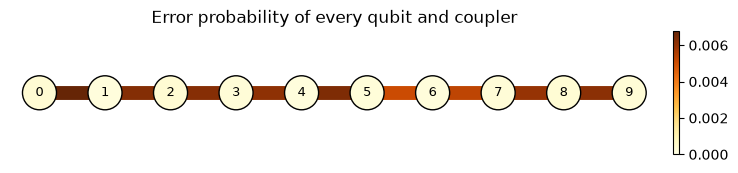

In [2]:
import matplotlib.pyplot as plt
from qiskit.quantum_info import PauliLindbladMap
from qiskit_paulice.noise_models import NoiseModel


def device_rates(*qubits):
    """The device's fixed random rate for every Pauli generator on one qubit or one coupler."""
    rng = np.random.default_rng([SEED, *qubits])
    paulis = ["X", "Y", "Z"] if len(qubits) == 1 else [p + q for p in "IXYZ" for q in "IXYZ"][1:]
    scale = 5e-5 if len(qubits) == 1 else 2e-4
    return {pauli: scale * rng.uniform(0.5, 1.5) for pauli in paulis}


def noise_map(qubits, couplers):
    """The Pauli-Lindblad map of a layer: every qubit's and every coupler's generators."""
    terms = [(p, (i,), r) for i, q in enumerate(qubits) for p, r in device_rates(q).items()]
    for a, b in couplers:
        pair = (qubits.index(a), qubits.index(b))
        terms += [(p, pair, r) for p, r in device_rates(a, b).items()]
    return PauliLindbladMap.from_sparse_list(terms, num_qubits=len(qubits))


payload_maps = [noise_map(list(range(NUM_QUBITS)), layer) for layer in payload_layers]
noise_model = NoiseModel.from_pauli_lindblad_maps(payload_maps)


def error_probability(*qubits):
    """The probability that at least one of the generators on ``qubits`` fires."""
    return 1 - np.exp(-2 * sum(device_rates(*qubits).values()))


couplers = [edge for layer in payload_layers for edge in layer]
norm = plt.Normalize(0, max(error_probability(*edge) for edge in couplers))
fig, ax = plt.subplots(figsize=(9, 1.6))
for edge in couplers:
    ax.plot(
        edge,
        [0, 0],
        lw=10,
        color=plt.cm.YlOrBr(norm(error_probability(*edge))),
        solid_capstyle="butt",
    )
qubits = ax.scatter(
    range(NUM_QUBITS),
    [0] * NUM_QUBITS,
    s=600,
    c=[error_probability(q) for q in range(NUM_QUBITS)],
    cmap="YlOrBr",
    norm=norm,
    edgecolor="black",
    zorder=2,
)
for q in range(NUM_QUBITS):
    ax.text(q, 0, str(q), ha="center", va="center", fontsize=9)
ax.set_axis_off()
ax.set_title("Error probability of every qubit and coupler")
fig.colorbar(qubits, ax=ax, fraction=0.05, pad=0.02);

### 3. Add Pauli checks

`add_pauli_checks` adds one check per target qubit, committing at each step the check that most lowers the cost: with `cost="gamma"` that is the $\gamma$ of the noise the checks leave undetected. We target every qubit and keep the last variant, which carries all ten checks. The four-qubit toy below shows what the checks look like: each ancilla, prepared in $|0\rangle$, is entangled with the payload at the points the search chose, and its syndrome is the parity of the bits in its `check_support`.

10 checks lower the cost from 1.143 to 1.011; check supports: ((0, 1, 10), (0, 11), (0, 1, 2, 4, 5, 12), (3, 13), (5, 14), (4, 15), (6, 16), (17,), (8, 18), (19,))


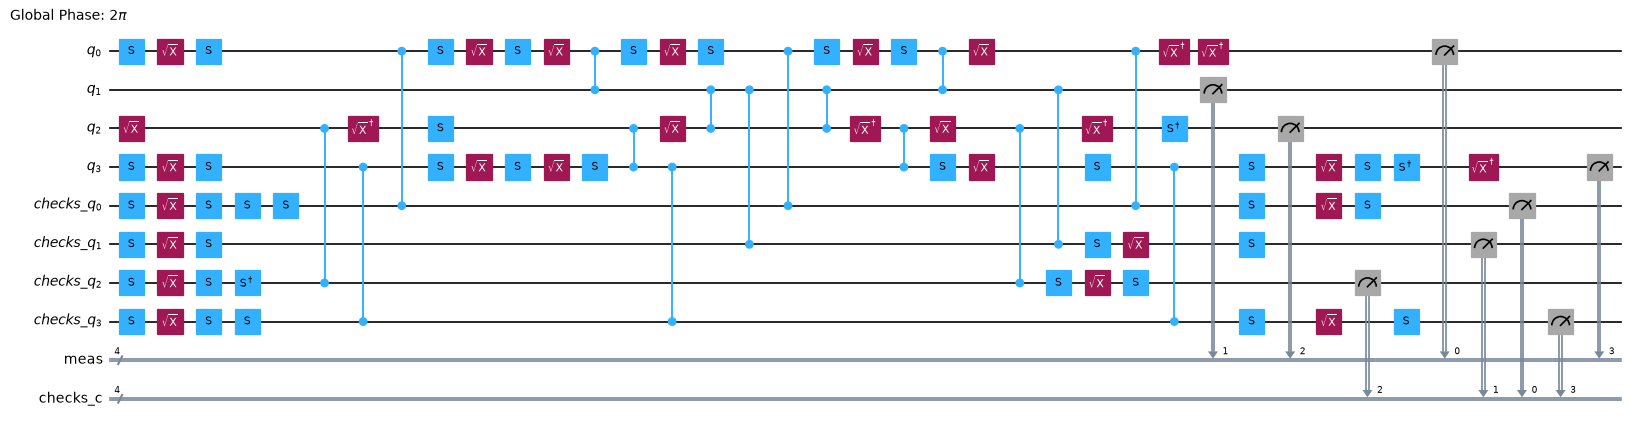

In [3]:
from qiskit_paulice import add_pauli_checks

checked = add_pauli_checks(circuit, list(range(NUM_QUBITS)), noise_model, seed=SEED)
print(f"{len(checked[-1].check_support)} checks lower the cost from {checked[0].cost:.3f}", end=" ")
print(f"to {checked[-1].cost:.3f}; check supports: {checked[-1].check_support}")
checked = checked[-1]

toy_model = NoiseModel.from_pauli_lindblad_maps(
    [noise_map([0, 1, 2, 3], [(0, 1), (2, 3)]), noise_map([0, 1, 2, 3], [(1, 2)])]
)
toy = add_pauli_checks(mirror_brickwork(4, 2, np.random.default_rng(3)), [0, 1, 2, 3], toy_model)
toy[-1].circuit.draw("mpl", fold=-1, scale=0.6, idle_wires=False)

### 4. Box the circuit and shade its noise by detectability

`CheckedCircuit.box` groups the executed circuit, ancillas and check gates included, into the annotated boxes `samplomatic` uses for twirling, noise learning and sampling. Every check gate is scheduled into a box of its own, so the unique layers to learn are the payload's two plus one small layer per check, however deep the circuit. The device's map for each layer follows from its qubits and couplers (a box's map indexes the box's qubits in physical order).

`create_postselected_noise_mask` propagates each check's *detector*, the $Z$ string on its `check_support`, backward through the boxed circuit and zeroes every generator that anticommutes with one at its injection point. The result is what `samplomatic` calls `local_scales`, and the function also returns the sampling cost $\gamma'^2$ of inverting only the surviving generators. The chart shows every noise box in circuit order: the checks cover most of the noise, and what is left for PEC costs a fraction of inverting everything.

44 noise boxes of 12 unique layers; the checks detect 81% of the noise


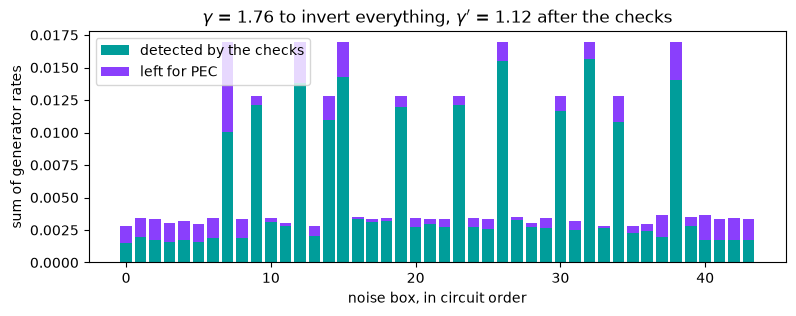

In [4]:
from qiskit.quantum_info import Pauli, PauliList
from qiskit_mitigation import PEC
from qiskit_mitigation.noise import create_postselected_noise_mask
from samplomatic.annotations import InjectNoise
from samplomatic.utils import get_annotation


def layer_maps(boxed):
    """The device's map for every noise box of ``boxed``, keyed by ``InjectNoise.ref``."""
    maps = {}
    for instruction in boxed.data:
        if instruction.operation.name != "box":
            continue
        inject = get_annotation(instruction.operation, InjectNoise)
        if inject is None or not inject.ref or inject.ref in maps:
            continue
        body = instruction.operation.blocks[0]
        physical = {
            q: boxed.find_bit(instruction.qubits[body.find_bit(q).index]).index for q in body.qubits
        }
        couplers = [
            tuple(physical[q] for q in gate.qubits) for gate in body.data if len(gate.qubits) == 2
        ]
        maps[inject.ref] = noise_map(sorted(physical.values()), couplers)
    return maps


def detectors(checked):
    """The Z string on each check's support: the operator whose outcome post-selection fixes."""
    num_qubits = checked.circuit.num_qubits
    return PauliList(
        [
            "".join("Z" if q in s else "I" for q in reversed(range(num_qubits)))
            for s in checked.check_support
        ]
    )


boxed = checked.box(payload_layers=payload_layers)
maps = layer_maps(boxed)
local_scales, cost = create_postselected_noise_mask(boxed, maps, detectors(checked))
gamma, gamma_qed = PEC.calculate_gamma(boxed, maps, 1), cost**0.5

boxes = {  # the modifier of every noise box in circuit order -> its layer
    inject.modifier_ref: inject.ref
    for instruction in boxed.data
    if instruction.operation.name == "box"
    and (inject := get_annotation(instruction.operation, InjectNoise)) is not None
    and inject.ref
}
total = np.array([maps[ref].rates.sum() for ref in boxes.values()])
undetected = np.array([maps[ref].rates @ local_scales[modifier] for modifier, ref in boxes.items()])
print(
    f"{len(boxes)} noise boxes of {len(maps)} unique layers; the checks detect {1 - undetected.sum() / total.sum():.0%} of the noise"
)

fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(range(len(boxes)), total - undetected, color="#009d9a", label="detected by the checks")
ax.bar(
    range(len(boxes)), undetected, bottom=total - undetected, color="#8a3ffc", label="left for PEC"
)
ax.set(xlabel="noise box, in circuit order", ylabel="sum of generator rates")
ax.set_title(
    f"$\\gamma$ = {gamma:.2f} to invert everything, $\\gamma'$ = {gamma_qed:.2f} after the checks"
)
ax.legend();

### 5. Sample the twirled circuit with and without noise inversion

`samplomatic.build` turns the boxed circuit into a parametrized template and a samplex that draws twirls, basis changes and, when `noise_scales` is $-1$, the Pauli insertions and signs that invert the maps, restricted to the generators that `local_scales` keeps. The device noise is applied by appending each layer's `PauliLindbladError` after the barrier that closes its box, and the Clifford circuits run on Aer's stabilizer simulator.

Three sample sets serve four methods: the baseline with no inversion gives both the raw and the error-detected estimate, PEC inverts every generator, and QED + PEC inverts only the undetected ones. The precision of a PEC estimate is set by the number of randomizations rather than shots, since every shot in a randomization shares its sign, so the inverting arms get many randomizations of few shots.

In [5]:
import samplomatic
from qiskit_aer import AerSimulator
from qiskit_aer.noise import PauliLindbladError

template, samplex = samplomatic.build(boxed)


def add_device_noise(template, maps):
    """Append each layer's Pauli-Lindblad channel after the barrier that closes its box."""
    noisy = template.copy_empty_like()
    for instruction in template.data:
        noisy.append(instruction)
        label = instruction.operation.label or ""
        if (
            instruction.operation.name == "barrier"
            and label.startswith("R")
            and "inject_noise=" in label
        ):
            layer = maps[label.split("inject_noise=")[1]]
            qubits = sorted(template.find_bit(q).index for q in instruction.qubits)
            paulis = PauliList(
                [
                    "".join(
                        dict(zip(indices, pauli, strict=True)).get(q, "I")
                        for q in reversed(range(len(qubits)))
                    )
                    for pauli, indices, _ in layer.to_sparse_list()
                ]
            )
            noisy.append(PauliLindbladError(paulis, list(layer.rates)).to_instruction(), qubits)
    return noisy


def to_clifford(bound):
    """Replace the twirl's ``rz(k pi/2)`` gates by Clifford gates for the stabilizer simulator."""
    out = bound.copy_empty_like()
    for instruction in bound.data:
        if instruction.operation.name == "rz":
            k = round(float(instruction.operation.params[0]) / (np.pi / 2)) % 4
            if k:
                getattr(out, ["id", "s", "z", "sdg"][k])(instruction.qubits[0])
        else:
            out.append(instruction)
    return out


noisy_template = add_device_noise(template, maps)
simulator = AerSimulator(method="stabilizer", seed_simulator=SEED)
z_basis = {
    s.name: np.ones(s.shape, dtype=np.uint8) for s in samplex.inputs().get_specs("basis_changes")
}


def sample(noise_scale, local_scales, num_randomizations, shots, seed):
    """Draw randomizations from the samplex and run them on the noisy simulator."""
    inputs = samplex.inputs().bind(
        pauli_lindblad_maps=maps,
        local_scales=local_scales,
        **z_basis,
        **{s.name: noise_scale for s in samplex.inputs().get_specs("noise_scales")},
    )
    outputs = samplex.sample(inputs, num_randomizations=num_randomizations, rng=seed)
    circuits = [
        to_clifford(noisy_template.assign_parameters(v)) for v in outputs["parameter_values"]
    ]
    result = simulator.run(circuits, shots=shots, memory=True).result()
    bits = [
        [[c == "1" for c in shot.replace(" ", "")[::-1]] for shot in result.get_memory(r)]
        for r in range(num_randomizations)
    ]
    return outputs, np.array(bits)


everything = {modifier: np.ones_like(scales) for modifier, scales in local_scales.items()}
runs = {
    "baseline": sample(0.0, everything, num_randomizations=256, shots=64, seed=1),
    "PEC": sample(-1.0, everything, num_randomizations=4096, shots=8, seed=2),
    "QED + PEC": sample(-1.0, local_scales, num_randomizations=4096, shots=8, seed=3),
}
for name, (outputs, bits) in runs.items():
    signs = np.asarray(outputs["pauli_signs"]).reshape(len(bits), -1).sum(axis=1) % 2
    print(
        f"{name:10s} {bits.shape[0]:5d} randomizations x {bits.shape[1]:2d} shots, {signs.mean():5.1%} with a negative sign"
    )

baseline     256 randomizations x 64 shots,  0.0% with a negative sign
PEC         4096 randomizations x  8 shots, 21.4% with a negative sign
QED + PEC   4096 randomizations x  8 shots,  5.2% with a negative sign


### 6. Undo the measurement twirl and post-select

Twirling flips measured bits deterministically within each randomization, and the samplex reports which (`measurement_flips.<register>`). Every measured bit, payload and ancilla alike, is XORed with its flip before anything else is done with it; post-selecting on the raw bits would keep exactly the wrong shots in every randomization whose twirl flips a check, and nothing about the result would look wrong. A shot is then accepted if every check's parity is even (`add_pauli_checks` measures qubit $q$ into classical bit $q$, so the bits can be read by qubit index).

The histogram is a consistency check on the mask: the Paulis that QED + PEC inserts commute with every detector, so they must not change the post-selection statistics. The accepted shots per randomization follow the binomial of the baseline's acceptance rate.

the checks accept 79.4% of the baseline shots and 79.8% of the QED + PEC shots (8 per randomization)


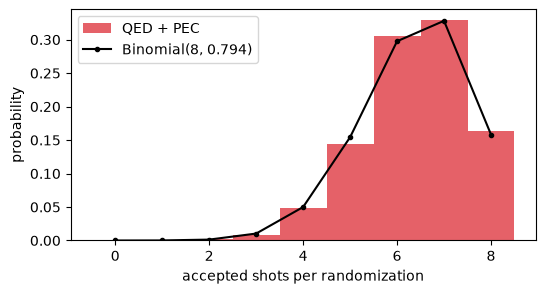

In [6]:
from math import comb

parity = np.array(
    [[q in support for q in range(boxed.num_qubits)] for support in checked.check_support],
    dtype=int,
)
payload = [checked.circuit.find_bit(clbit).index for clbit in checked.circuit.cregs[0]]


def undo_twirl(outputs, bits):
    """XOR every measured bit with the flip the twirl put on it."""
    bits = bits.copy()
    for creg in checked.circuit.cregs:
        clbits = [checked.circuit.find_bit(clbit).index for clbit in creg]
        bits[..., clbits] ^= np.asarray(outputs[f"measurement_flips.{creg.name}"], dtype=bool)
    return bits


def accepted(bits):
    """Which shots pass every check: all syndrome parities are even."""
    return ~((bits @ parity.T) % 2).any(axis=-1)


runs = {name: (outputs, undo_twirl(outputs, bits)) for name, (outputs, bits) in runs.items()}
rate = accepted(runs["baseline"][1]).mean()
counts = accepted(runs["QED + PEC"][1]).sum(axis=1)
print(
    f"the checks accept {rate:.1%} of the baseline shots and {counts.mean() / 8:.1%} of the QED + PEC shots (8 per randomization)"
)

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(
    counts, bins=np.arange(10) - 0.5, density=True, color="#da1e28", alpha=0.7, label="QED + PEC"
)
ax.plot(
    range(9),
    [comb(8, k) * rate**k * (1 - rate) ** (8 - k) for k in range(9)],
    "k.-",
    label=f"Binomial(8, {rate:.3f})",
)
ax.set(xlabel="accepted shots per randomization", ylabel="probability")
ax.legend();

### 7. Estimate the expectation values

With signs and post-selection in play the estimator is a ratio: for each qubit, the sign-weighted sum of its accepted outcomes over the sign-weighted number of accepted shots. The sampling overhead cancels between numerator and denominator, and the error bar treats the randomizations as the independent units, since the shots of one randomization share its sign and its inserted Paulis. The same function serves all four methods; without signs or post-selection it reduces to the plain mean.

Error detection alone leaves a residual bias of about a percent, from the errors the checks cannot see; PEC alone is unbiased but noisy, having paid $\gamma^2$ to invert everything; QED + PEC is both unbiased and precise. Its error bars are smaller than plain PEC's by more than the ratio of the overheads, because the post-selected shots are nearly noise-free and so have little variance of their own.

raw        mean <Z> = 0.9090 ± 0.0010
QED        mean <Z> = 0.9899 ± 0.0004
PEC        mean <Z> = 0.9930 ± 0.0037
QED + PEC  mean <Z> = 0.9993 ± 0.0009


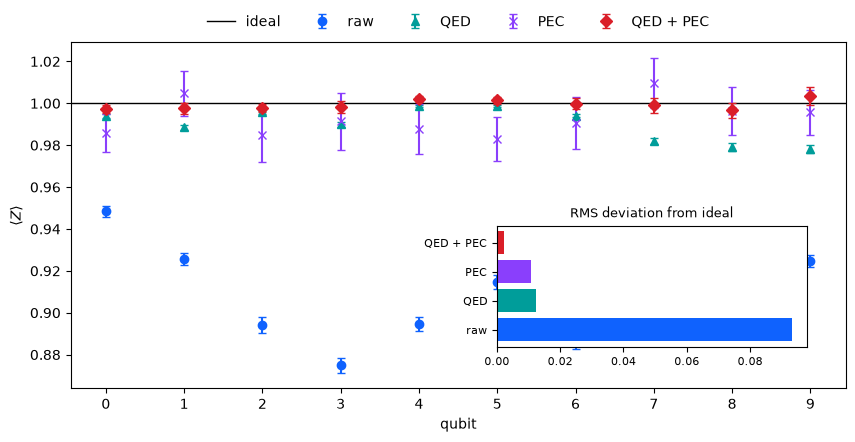

In [7]:
def estimate(bits, signs, keep):
    """Per-qubit <Z> and standard errors: a ratio of sign-weighted sums over randomizations."""
    numerator = signs[:, None] * (keep[..., None] * (1 - 2 * bits[..., payload])).sum(axis=1)
    denominator = signs * keep.sum(axis=1)
    values = numerator.sum(axis=0) / denominator.sum()
    errors = np.sqrt(((numerator - values * denominator[:, None]) ** 2).sum(axis=0)) / abs(
        denominator.sum()
    )
    return values, errors


def shots(run, postselect, pec):
    """The bits of one sample set with the sign of each randomization and the mask of accepted shots."""
    outputs, bits = runs[run]
    signs = np.ones(len(bits))
    if pec:
        signs -= 2 * (np.asarray(outputs["pauli_signs"]).reshape(len(bits), -1).sum(axis=1) % 2)
    keep = accepted(bits) if postselect else np.ones(bits.shape[:2], dtype=bool)
    return bits, signs, keep


results = {
    "raw": estimate(*shots("baseline", postselect=False, pec=False)),
    "QED": estimate(*shots("baseline", postselect=True, pec=False)),
    "PEC": estimate(*shots("PEC", postselect=False, pec=True)),
    "QED + PEC": estimate(*shots("QED + PEC", postselect=True, pec=True)),
}
for name, (values, errors) in results.items():
    print(
        f"{name:10s} mean <Z> = {values.mean():.4f} ± {np.sqrt((errors**2).sum()) / NUM_QUBITS:.4f}"
    )

styles = {
    "raw": ("o", "#0f62fe"),
    "QED": ("^", "#009d9a"),
    "PEC": ("x", "#8a3ffc"),
    "QED + PEC": ("D", "#da1e28"),
}
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axhline(1, color="black", lw=1, label="ideal")
for name, (values, errors) in results.items():
    ax.errorbar(
        range(NUM_QUBITS),
        values,
        errors,
        fmt=styles[name][0],
        color=styles[name][1],
        capsize=3,
        label=name,
    )
ax.set(xlabel="qubit", ylabel=r"$\langle Z \rangle$", xticks=range(NUM_QUBITS))
ax.legend(ncols=5, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
inset = ax.inset_axes([0.55, 0.12, 0.4, 0.35])
inset.barh(
    range(4),
    [np.sqrt(((v - 1) ** 2).mean()) for v, _ in results.values()],
    color=[s[1] for s in styles.values()],
)
inset.set_yticks(range(4), list(results), fontsize=8)
inset.set_title("RMS deviation from ideal", fontsize=9)
inset.tick_params(labelsize=8);

The convergence of the two inverting arms makes the saving explicit: evaluated on growing prefixes of the same sweep, QED + PEC is converged after a few hundred randomizations, while plain PEC needs thousands and its error bar is still several times larger at the end.

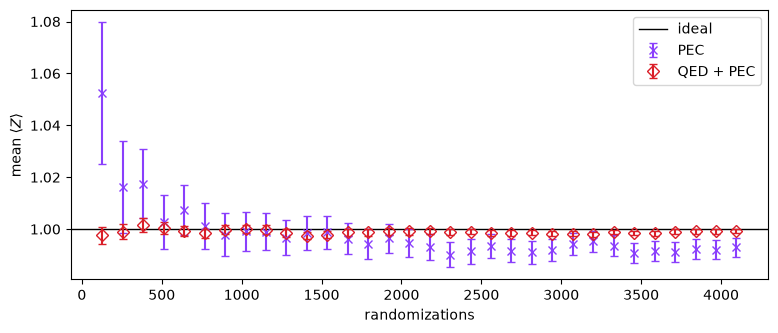

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.axhline(1, color="black", lw=1, label="ideal")
for name in ("PEC", "QED + PEC"):
    bits, signs, keep = shots(name, postselect=name != "PEC", pec=True)
    prefixes = np.arange(128, len(bits) + 1, 128)
    points = [estimate(bits[:n], signs[:n], keep[:n]) for n in prefixes]
    ax.errorbar(
        prefixes,
        [values.mean() for values, _ in points],
        [np.sqrt((errors**2).sum()) / NUM_QUBITS for _, errors in points],
        fmt=styles[name][0],
        color=styles[name][1],
        capsize=3,
        mfc="none",
        label=name,
    )
ax.set(xlabel="randomizations", ylabel=r"mean $\langle Z \rangle$")
ax.legend();

### 8. Compute the first-order truncation bias

The mask zeroes a generator on the grounds that post-selection removes it. That is exact for one error at a time, but a shot carries every error that fired, and two detected errors can combine into one the checks do not see: the checks then accept the shot, and PEC, which inverts only the masked model, cancels neither. The estimate is biased by $O(\lambda^2)$ in the rates.

Because the circuit is Clifford, the effect of a set of errors on every check and every payload $Z$ is the XOR of the individual effects, so the bias can be computed exactly under the model without simulating any circuit. `create_postselected_noise_mask` with a single detector tells which generators flip it, which gives each generator instance a signature over all checks and payload $Z$s; a Monte Carlo then draws error configurations, keeps the ones no check flags, and divides their $\langle Z_q \rangle$ by what the first-order inversion cancels. The result is the value QED + PEC converges to, and its deviation from $1$ is the bias.

this circuit: predicted bias 0.026%, measured deviation 0.069 ± 0.087%
L =   6 entangling layers: accepted 86.1%, QED + PEC bias 0.010%


L =  12 entangling layers: accepted 79.8%, QED + PEC bias 0.027%


L =  24 entangling layers: accepted 66.3%, QED + PEC bias 0.078%


L =  48 entangling layers: accepted 45.4%, QED + PEC bias 0.164%


L =  96 entangling layers: accepted 21.0%, QED + PEC bias 0.363%


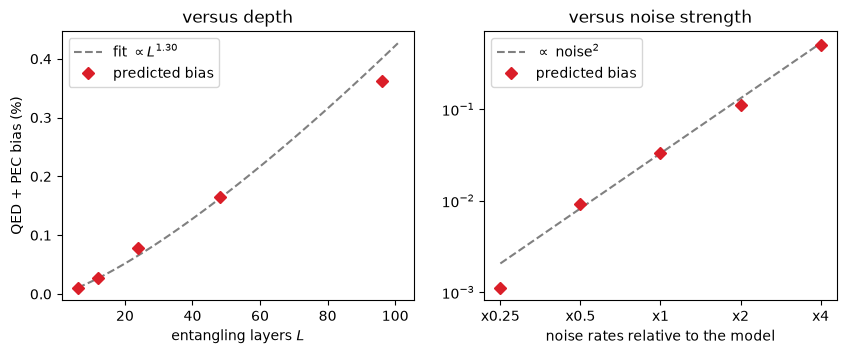

In [9]:
def signatures(checked, boxed, maps, local_scales):
    """Per generator instance: the bitmask of the checks (low bits) and payload Zs (high bits) it flips, its rate, and its mask value."""
    num_qubits = checked.circuit.num_qubits
    paulis = list(detectors(checked)) + [
        Pauli("I" * (num_qubits - 1 - q) + "Z" + "I" * q) for q in range(NUM_QUBITS)
    ]
    masks = [create_postselected_noise_mask(boxed, maps, [pauli])[0] for pauli in paulis]
    boxes = {
        inject.modifier_ref: inject.ref
        for inject in (
            get_annotation(i.operation, InjectNoise)
            for i in boxed.data
            if i.operation.name == "box"
        )
        if inject is not None and inject.ref
    }
    flips = np.concatenate(
        [np.array([1 - mask[m] for mask in masks], dtype=np.uint64).T for m in boxes]
    )
    flips = flips @ (np.uint64(1) << np.arange(len(paulis), dtype=np.uint64))
    return (
        flips,
        np.concatenate([maps[ref].rates for ref in boxes.values()]),
        np.concatenate([local_scales[m] for m in boxes]),
    )


def predicted_bias(checked, boxed, maps, local_scales, shots, rng, noise_factor=1.0):
    """Exact Pauli-level Monte Carlo of QED + first-order PEC under the model: the mean bias in percent."""
    flips, rates, scales = signatures(checked, boxed, maps, local_scales)
    rates = noise_factor * rates
    num_checks = len(checked.check_support)
    net = np.zeros(shots, dtype=np.uint64)
    for flip, probability in zip(flips, (1 - np.exp(-2 * rates)) / 2, strict=True):
        count = rng.binomial(shots, probability)
        if count and flip:
            np.bitwise_xor.at(net, rng.integers(0, shots, count), flip)
    kept = net[(net & np.uint64((1 << num_checks) - 1)) == 0]
    biases = []
    for q in range(NUM_QUBITS):
        bit = np.uint64(1 << (num_checks + q))
        value = 1 - 2 * ((kept & bit) != 0).mean()
        cancelled = np.exp(-2 * (rates * scales)[(flips & bit) != 0].sum())
        biases.append(1 - value / cancelled)
    return 100 * np.mean(biases), len(kept) / shots


bias, acceptance = predicted_bias(
    checked, boxed, maps, local_scales, 4_000_000, np.random.default_rng(0)
)
measured = 100 * (1 - results["QED + PEC"][0].mean())
print(
    f"this circuit: predicted bias {bias:.3f}%, measured deviation {measured:.3f} ± {100 * np.sqrt((results['QED + PEC'][1] ** 2).sum()) / NUM_QUBITS:.3f}%"
)

depths, biases = [], []
for forward_layers in (3, 6, 12, 24, 48):
    rng = np.random.default_rng(SEED + forward_layers)
    checked_deep = add_pauli_checks(
        mirror_brickwork(NUM_QUBITS, forward_layers, rng),
        list(range(NUM_QUBITS)),
        noise_model,
        seed=SEED,
    )[-1]
    boxed_deep = checked_deep.box(payload_layers=payload_layers)
    maps_deep = layer_maps(boxed_deep)
    scales_deep, _ = create_postselected_noise_mask(boxed_deep, maps_deep, detectors(checked_deep))
    bias, acceptance = predicted_bias(
        checked_deep, boxed_deep, maps_deep, scales_deep, 4_000_000, rng
    )
    depths.append(2 * forward_layers)
    biases.append(bias)
    print(
        f"L = {2 * forward_layers:3d} entangling layers: accepted {acceptance:5.1%}, QED + PEC bias {bias:.3f}%"
    )
factors = [0.25, 0.5, 1, 2, 4]
scaled = [
    predicted_bias(checked, boxed, maps, local_scales, 4_000_000, np.random.default_rng(1), f)[0]
    for f in factors
]
exponent, log_prefactor = np.polyfit(np.log(depths), np.log(biases), 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
grid = np.linspace(min(depths), max(depths) * 1.05, 100)
axes[0].plot(
    grid,
    np.exp(log_prefactor) * grid**exponent,
    "--",
    color="gray",
    label=f"fit $\\propto L^{{{exponent:.2f}}}$",
)
axes[0].plot(depths, biases, "D", color="#da1e28", label="predicted bias")
axes[0].set(xlabel="entangling layers $L$", ylabel="QED + PEC bias (%)", title="versus depth")
axes[1].loglog(
    factors, scaled[2] * np.array(factors) ** 2, "--", color="gray", label="$\\propto$ noise$^2$"
)
axes[1].loglog(factors, scaled, "D", color="#da1e28", label="predicted bias")
axes[1].set(xlabel="noise rates relative to the model", title="versus noise strength")
axes[1].set_xticks(factors, [f"x{f:g}" for f in factors], minor=False)
axes[1].minorticks_off()
for ax in axes:
    ax.legend()

The bias is well below the statistical error of the run above, and it is second order in the rates: halving the noise quarters it. With depth it grows faster than linearly, since deeper circuits give pairs of detected errors more chances to combine into something undetected; the exponent depends on the geometry of the checks. This is the quantity to budget against: once the statistical error of QED + PEC is pushed below it, deeper circuits need better coverage (more or better-placed checks) or a less noisy device, not more shots. The same Monte Carlo doubles as a planning tool, since it costs seconds rather than a run.